In [1]:

#Find dataset paths
from pathlib import Path

# List all CSV files in Kaggle Input
for path in Path("/kaggle/input").rglob("*.csv"):
    print(path)

import pandas as pd
import numpy as np
import json

from pathlib import Path

from sklearn.model_selection import (
    PredefinedSplit,
    RandomizedSearchCV,
    cross_validate,
    cross_val_predict
)

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_fscore_support,
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

from xgboost import XGBClassifier

RANDOM_STATE = 42

# Automatically locate the two datasets
csv_files = list(Path("/kaggle/input").rglob("*.csv"))

train_paths = [p for p in csv_files if p.name == "train_folds.csv"]
test_paths = [p for p in csv_files if p.name == "test.csv"]

assert len(train_paths) == 1, f"Train paths: {train_paths}"
assert len(test_paths) == 1, f"Test paths: {test_paths}"

train = pd.read_csv(train_paths[0])
test = pd.read_csv(test_paths[0])

print("Train shape:", train.shape)
print("Test shape:", test.shape)

display(train.head())
display(test.head())


/kaggle/input/datasets/bchtrnng/test-csv/test.csv
/kaggle/input/datasets/bchtrnng/train-folds/train_folds.csv
Train shape: (143771, 18)
Test shape: (70814, 17)


,add_count,remove_count,unique_products_in_cart,view_count,detail_count,add_to_detail_ratio,search_count,unique_categories_viewed,avg_price_bucket,max_price_bucket,nevents,unique_products_viewed,avg_dwell_time,session_duration,hod,dow,SCA,fold
0,1,1,1,24,0,1.000000,5,0,7.0,7.0,26,0,30.422320,760.558,12,4,0,9
1,2,0,2,10,4,0.400000,0,1,3.0,3.0,16,2,95.361364,1048.975,7,4,0,6
2,1,3,1,26,4,0.200000,1,2,4.0,8.0,34,4,41.664793,1208.279,7,3,1,6
3,1,1,1,43,18,0.052632,0,1,10.0,10.0,63,5,21.466091,944.508,9,2,1,7
4,1,0,1,67,10,0.090909,2,3,8.0,10.0,78,9,28.922493,1937.807,20,7,0,5


,add_count,remove_count,unique_products_in_cart,view_count,detail_count,add_to_detail_ratio,search_count,unique_categories_viewed,avg_price_bucket,max_price_bucket,nevents,unique_products_viewed,avg_dwell_time,session_duration,hod,dow,SCA
0,2,1,2,18,3,0.50,0,2,7.0,7.0,24,3,56.669500,1133.390,10,3,0
1,3,19,1,16,4,0.60,0,1,10.0,10.0,42,2,12.364811,457.498,7,6,0
2,1,0,1,3,1,0.50,0,1,7.0,7.0,5,1,23.527333,70.582,10,5,1
3,1,0,1,7,3,0.25,0,1,8.0,9.0,11,2,10.602143,74.215,15,7,1
4,1,1,1,19,3,0.25,1,1,10.0,10.0,24,3,143.245350,2864.907,10,4,1


In [2]:
 #Feature selection

features = [
    "add_count",
    "remove_count",
    "view_count",
    "detail_count",
    "add_to_detail_ratio",
    "search_count",
    "unique_categories_viewed",
    "avg_price_bucket",
    "max_price_bucket",
    "unique_products_viewed",
    "avg_dwell_time",
    "session_duration",
    "hod",
    "dow"
]

target = "SCA"

# Verify the required columns exist
assert set(features + [target, "fold"]).issubset(train.columns)
assert set(features + [target]).issubset(test.columns)

# Confirm expected row counts
assert len(train) == 143771
assert len(test) == 70814

# Select X and y
X_train = train[features].copy()
y_train = train[target].astype(int)

X_test = test[features].copy()
y_test = test[target].astype(int)

assert set(y_train.unique()) == {0, 1}
assert set(y_test.unique()) == {0, 1}

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)
#Check missing values

print("Missing values in training data:")
print(X_train.isnull().sum())

print("\nMissing values in test data:")
print(X_test.isnull().sum())


X_train: (143771, 14)
y_train: (143771,)
X_test: (70814, 14)
y_test: (70814,)
Missing values in training data:
add_count                     0
remove_count                  0
view_count                    0
detail_count                  0
add_to_detail_ratio           0
search_count                  0
unique_categories_viewed      0
avg_price_bucket            147
max_price_bucket            134
unique_products_viewed        0
avg_dwell_time                0
session_duration              0
hod                           0
dow                           0
dtype: int64

Missing values in test data:
add_count                    0
remove_count                 0
view_count                   0
detail_count                 0
add_to_detail_ratio          0
search_count                 0
unique_categories_viewed     0
avg_price_bucket            70
max_price_bucket            64
unique_products_viewed       0
avg_dwell_time               0
session_duration             0
hod                       

In [3]:
#Create Pipeline

pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "model",
        XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=1,
            tree_method="hist"
        )
    )
])

print(pipeline)
#PredefinedSplit

cv = PredefinedSplit(
    test_fold=train["fold"].to_numpy()
)

print("Number of folds:", cv.get_n_splits())

for fold, (train_idx, val_idx) in enumerate(
    cv.split()
):
    print(
        f"Fold {fold}: "
        f"Train={len(train_idx)}, "
        f"Validation={len(val_idx)}"
    )


Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('model',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=True, eval_metric='logloss',
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
      

In [4]:
#Define hyperparameter search space

param_distributions = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [3, 4, 5, 6, 8],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "model__min_child_weight": [1, 3, 5],
    "model__reg_lambda": [1, 5, 10]
}
#Run RandomizedSearchCV

search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True,
    verbose=2,
    return_train_score=False
)

search.fit(X_train, y_train)

print("Best parameters:")
print(search.best_params_)

print("\nBest CV RMSE:")
print(-search.best_score_)
#Display tuning results

tuning_results = pd.DataFrame(
    search.cv_results_
)

tuning_results["rmse"] = (
    -tuning_results["mean_test_score"]
)

top10 = tuning_results.sort_values(
    "rmse", ascending=True
).head(10)

display(
    top10[
        [
            "rank_test_score",
            "rmse",
            "std_test_score",
            "params"
        ]
    ]
)

best_model = search.best_estimator_

print("Best model:")
print(best_model)


Fitting 10 folds for each of 30 candidates, totalling 300 fits
[CV] END model__colsample_bytree=0.9, model__learning_rate=0.05, model__max_depth=3, model__min_child_weight=3, model__n_estimators=200, model__reg_lambda=10, model__subsample=0.9; total time=   3.4s
[CV] END model__colsample_bytree=0.9, model__learning_rate=0.05, model__max_depth=3, model__min_child_weight=3, model__n_estimators=200, model__reg_lambda=10, model__subsample=0.9; total time=   3.4s
[CV] END model__colsample_bytree=0.9, model__learning_rate=0.05, model__max_depth=3, model__min_child_weight=3, model__n_estimators=200, model__reg_lambda=10, model__subsample=0.9; total time=   3.5s
[CV] END model__colsample_bytree=0.7, model__learning_rate=0.03, model__max_depth=3, model__min_child_weight=5, model__n_estimators=500, model__reg_lambda=10, model__subsample=0.7; total time=   7.9s
[CV] END model__colsample_bytree=0.7, model__learning_rate=0.03, model__max_depth=3, model__min_child_weight=5, model__n_estimators=500, 

,rank_test_score,rmse,std_test_score,params
16,1,0.449297,0.001236,"{'model__subsample': 0.8, 'model__reg_lambda':..."
5,2,0.449374,0.001350,"{'model__subsample': 0.9, 'model__reg_lambda':..."
29,3,0.449404,0.001770,"{'model__subsample': 0.8, 'model__reg_lambda':..."
10,4,0.449545,0.001297,"{'model__subsample': 1.0, 'model__reg_lambda':..."
12,5,0.449630,0.001178,"{'model__subsample': 0.9, 'model__reg_lambda':..."
2,6,0.449723,0.001197,"{'model__subsample': 0.9, 'model__reg_lambda':..."
15,7,0.449823,0.001223,"{'model__subsample': 1.0, 'model__reg_lambda':..."
11,8,0.449838,0.001423,"{'model__subsample': 1.0, 'model__reg_lambda':..."
28,9,0.449893,0.001106,"{'model__subsample': 0.9, 'model__reg_lambda':..."
9,10,0.449962,0.001428,"{'model__subsample': 0.9, 'model__reg_lambda':..."


Best model:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('model',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=0.9, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=True, eval_metric='logloss',
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.03,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=6, max_leaves=None, min_child_weight=1,
                               missing=nan, m

In [5]:
#Evaluate the best model on the predefined folds

cv_scores = cross_validate(
    best_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "rmse": "neg_root_mean_squared_error",
        "auc": "roc_auc"
    },
    n_jobs=-1
)

rmse_scores = -cv_scores["test_rmse"]
auc_scores = cv_scores["test_auc"]

cv_10fold = {
    "rmse_mean": float(np.mean(rmse_scores)),
    "rmse_std": float(np.std(rmse_scores)),
    "auc_mean": float(np.mean(auc_scores)),
    "auc_std": float(np.std(auc_scores))
}

print(json.dumps(cv_10fold, indent=4))


{
    "rmse_mean": 0.44929735116314456,
    "rmse_std": 0.0012363046636774185,
    "auc_mean": 0.7753614590706264,
    "auc_std": 0.0033456340292591534
}


In [6]:
#Choose the classification threshold using OOF predictions

# Generate training predictions from models
# that did not train on the corresponding rows.

oof_proba = cross_val_predict(
    best_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("OOF shape:", oof_proba.shape)
print("First 10 probabilities:")
print(oof_proba[:10])
#Find the best threshold

thresholds = np.linspace(0.01, 0.99, 99)

threshold_results = []

for threshold in thresholds:
    y_pred = (oof_proba >= threshold).astype(int)

    score = f1_score(
        y_train,
        y_pred,
        average="macro",
        zero_division=0
    )

    threshold_results.append({
        "threshold": threshold,
        "macro_f1": score
    })

threshold_df = pd.DataFrame(threshold_results)

best_row = threshold_df.loc[
    threshold_df["macro_f1"].idxmax()
]

p_star = float(best_row["threshold"])

print("Best threshold:", p_star)
print("Best OOF Macro-F1:", best_row["macro_f1"])

display(
    threshold_df.sort_values(
        "macro_f1", ascending=False
    ).head(10)
)
#Predict test probabilities

p_test = best_model.predict_proba(
    X_test
)[:, 1]

p_test = np.clip(p_test, 0, 1)

print("Number of predictions:", len(p_test))
print("First 10 predictions:")
print(p_test[:10])
#Calculate main test metrics

mse = mean_squared_error(y_test, p_test)

metrics_test = {
    "rmse": float(np.sqrt(mse)),
    "mse": float(mse),
    "mae": float(
        mean_absolute_error(y_test, p_test)
    ),
    "r2": float(
        r2_score(y_test, p_test)
    ),
    "roc_auc": float(
        roc_auc_score(y_test, p_test)
    )
}

print(json.dumps(metrics_test, indent=4))


OOF shape: (143771,)
First 10 probabilities:
[0.76669866 0.8234918  0.913912   0.8902589  0.685364   0.4855575
 0.8107042  0.89606315 0.8273701  0.85034496]
Best threshold: 0.6900000000000001
Best OOF Macro-F1: 0.6636717279472764


,threshold,macro_f1
68,0.69,0.663672
67,0.68,0.663211
66,0.67,0.662313
69,0.70,0.662158
65,0.66,0.661247
70,0.71,0.659945
64,0.65,0.659548
71,0.72,0.657452
63,0.64,0.657029
72,0.73,0.654948


Number of predictions: 70814
First 10 predictions:
[0.62153614 0.41555095 0.7447355  0.7671365  0.93427247 0.9787137
 0.73849905 0.82658374 0.9881557  0.5704149 ]
{
    "rmse": 0.37532801984322833,
    "mse": 0.14087112247943878,
    "mae": 0.28309357166290283,
    "r2": 0.1640545129776001,
    "roc_auc": 0.7736140089003719
}


In [7]:
#Calculate classification metrics

def calculate_class_metrics(y_true, probabilities, threshold):

    y_pred = (
        probabilities >= threshold
    ).astype(int)

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=[0, 1],
            zero_division=0
        )
    )

    return {
        "threshold": float(threshold),

        "precision_1": float(precision[1]),
        "recall_1": float(recall[1]),
        "f1_1": float(f1[1]),

        "precision_0": float(precision[0]),
        "recall_0": float(recall[0]),
        "f1_0": float(f1[0]),

        "balanced_accuracy": float(
            balanced_accuracy_score(y_true, y_pred)
        ),

        "macro_f1": float(
            f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            )
        ),

        "pr_auc": float(
            average_precision_score(y_true, probabilities)
        ),

        "accuracy": float(
            accuracy_score(y_true, y_pred)
        )
    }


metrics_class = {
    "threshold_0_5": calculate_class_metrics(
        y_test, p_test, 0.5
    ),

    "threshold_p_star": calculate_class_metrics(
        y_test, p_test, p_star
    )
}

print(json.dumps(metrics_class, indent=4))
#Calculate baseline metrics

# Estimate abandonment rate using training data
baseline_probability = float(y_train.mean())

baseline_predictions = np.full(
    len(y_test),
    baseline_probability
)

baseline_mse = mean_squared_error(
    y_test,
    baseline_predictions
)

baseline_metrics = {
    "rmse": float(np.sqrt(baseline_mse)),
    "mse": float(baseline_mse),
    "mae": float(
        mean_absolute_error(y_test, baseline_predictions)
    ),
    "r2": float(
        r2_score(y_test, baseline_predictions)
    ),
    "roc_auc": 0.5
}

comparison = pd.DataFrame([
    {"model": "Baseline", **baseline_metrics},
    {"model": "XGBoost", **metrics_test}
])

display(comparison)


{
    "threshold_0_5": {
        "threshold": 0.5,
        "precision_1": 0.8090343845980973,
        "recall_1": 0.9708383524208483,
        "f1_1": 0.8825817629079973,
        "precision_0": 0.6013762595232244,
        "recall_0": 0.1610610149410913,
        "f1_0": 0.25407538158031356,
        "balanced_accuracy": 0.5659496836809698,
        "macro_f1": 0.5683285722441554,
        "pr_auc": 0.9261369389545531,
        "accuracy": 0.7971022679131246
    },
    "threshold_p_star": {
        "threshold": 0.6900000000000001,
        "precision_1": 0.8645455408870738,
        "recall_1": 0.8182880566692436,
        "f1_1": 0.8407810392921139,
        "precision_0": 0.4437228245913369,
        "recall_0": 0.530639110116501,
        "f1_0": 0.4833043582519034,
        "balanced_accuracy": 0.6744635833928723,
        "macro_f1": 0.6620426987720086,
        "pr_auc": 0.9261369389545531,
        "accuracy": 0.7565735589007824
    }
}


,model,rmse,mse,mae,r2,roc_auc
0,Baseline,0.410508,0.168517,0.337035,-1.436673e-11,0.500000
1,XGBoost,0.375328,0.140871,0.283094,1.640545e-01,0.773614


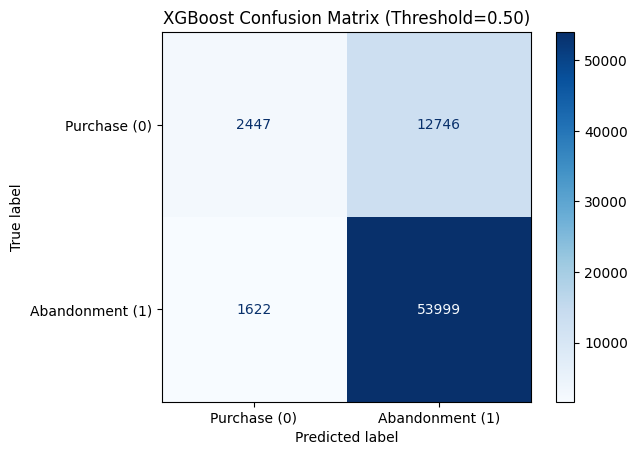

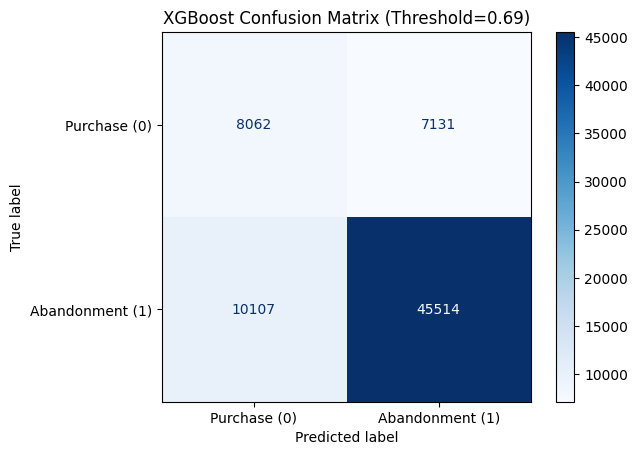

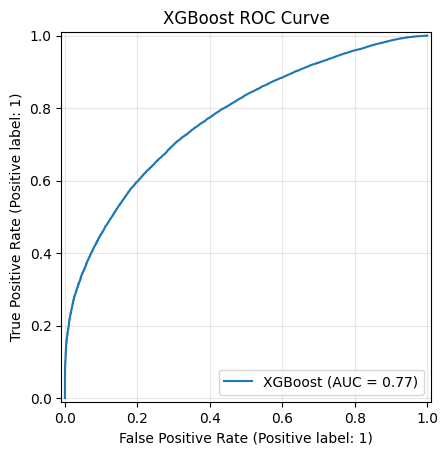

Saved to: /kaggle/working/xgboost_tran.json


In [8]:
#Plot confusion matrices

import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix
)

for threshold in [0.5, p_star]:
    y_pred = (p_test >= threshold).astype(int)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "Purchase (0)",
            "Abandonment (1)"
        ]
    )

    disp.plot(cmap="Blues", values_format="d")

    plt.title(
        f"XGBoost Confusion Matrix "
        f"(Threshold={threshold:.2f})"
    )

    plt.show()
#Plot ROC curve

from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    p_test,
    name="XGBoost"
)

plt.title("XGBoost ROC Curve")
plt.grid(alpha=0.3)
plt.show()
#Save JSON results

# Remove the Pipeline prefix from parameter names
best_params = {
    key.replace("model__", ""): value
    for key, value in search.best_params_.items()
}

results = {
    "model": "XGBoost",
    "case": 2,

    "features": features,
    "n_features": len(features),

    "n_train": len(X_train),
    "n_test": len(X_test),

    "random_state": RANDOM_STATE,

    "best_params": best_params,

    "cv_10fold": cv_10fold,

    "metrics_test": metrics_test,

    "p_star": p_star,

    "metrics_class": metrics_class,

    "baseline_metrics": baseline_metrics,

    "notes": {
        "algorithm": "XGBClassifier",
        "preprocessing": (
            "SimpleImputer(strategy='median') "
            "inside sklearn Pipeline"
        ),
        "validation": "PredefinedSplit, 10 folds",
        "tuning": "RandomizedSearchCV",
        "n_iter": 30,
        "tuning_scoring": "neg_root_mean_squared_error",
        "parameter_space": param_distributions,
        "prediction": "predict_proba(X)[:, 1]",
        "threshold_selection": (
            "OOF macro-F1 maximization "
            "using 99 thresholds from 0.01 to 0.99"
        ),
        "pr_auc_definition": "average_precision_score",
        "early_stopping": False,
        "test_usage": "Final evaluation only",
        "data_handling": (
            "No row deletion, no duplicate removal, "
            "no outlier clipping"
        )
    }
}

output_path = "/kaggle/working/xgboost_tran.json"

with open(output_path, "w") as f:
    json.dump(results, f, indent=4)

print("Saved to:", output_path)
